In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

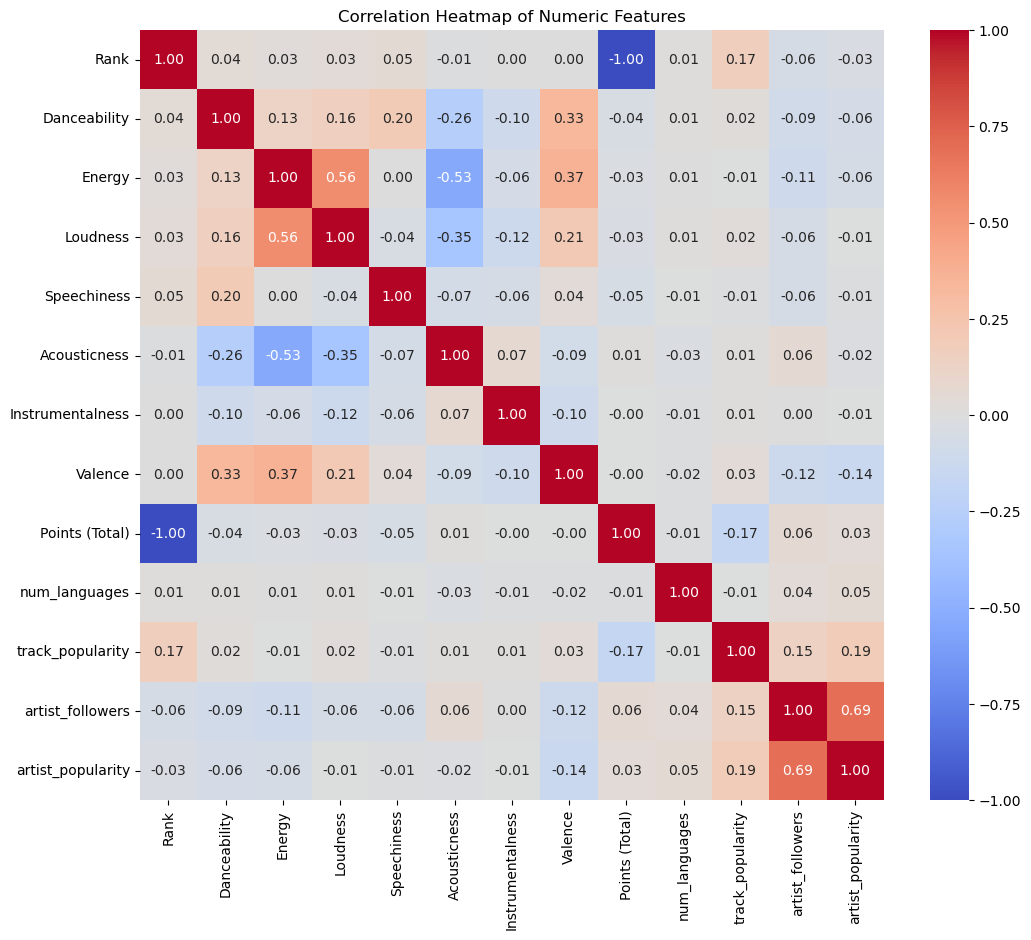

In [2]:
df = pd.read_csv("data/additional_features.csv")

# Assuming your DataFrame is df
numeric_cols = df.select_dtypes(include=['number']).columns
df_numeric = df[numeric_cols]

corr = df_numeric.corr()

plt.figure(figsize=(12,10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Correlation Heatmap of Numeric Features")
plt.show()


In [6]:
# Fill missing genres and split into lists
df['artist_genres_list'] = df['artist_genres'].fillna("").apply(lambda x: x.split(", "))

# Explode so each genre is a separate row
df_exploded = df.explode('artist_genres_list')

genre_counts = df_exploded['artist_genres_list'].value_counts().reset_index()
genre_counts.columns = ['genre', 'song_count']


genre_counts.to_csv("data/genre_counts.csv", index=False)


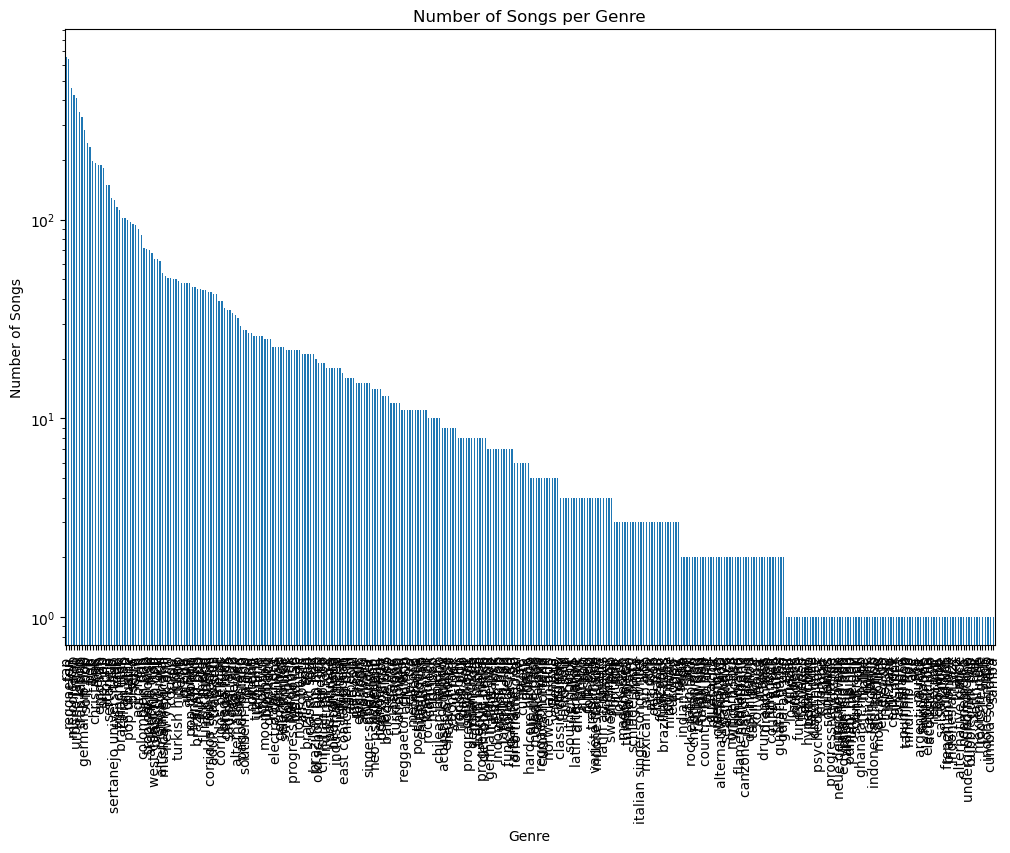

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

# Fill missing genres and split into lists
df['artist_genres_list'] = df['artist_genres'].fillna("").apply(lambda x: x.split(", "))

# Explode so each genre is a separate row
df_exploded = df.explode('artist_genres_list')

# Filter out empty strings
df_exploded = df_exploded[df_exploded['artist_genres_list'] != ""]

genre_counts = df_exploded['artist_genres_list'].value_counts()

plt.figure(figsize=(12,8))
genre_counts.plot(kind='bar', logy=True)
plt.xticks(rotation=90)
plt.xlabel("Genre")
plt.ylabel("Number of Songs")
plt.title("Number of Songs per Genre")
plt.show()
